# 03b. Apurement : une base provinciale sans cellule vide

Sentinelle Scolaire, défi 1.

L'apurement part du panel provincial de 2025 produit par l'étape 03 (47 provinces × 9 années scolaires, 2016-2017 à 2024-2025) et en fait une base complète, dont chaque valeur est tracée :

0. **Sélection** de 79 colonnes : 10 identifiants et 69 variables ; les autres restent dans le panel de l'étape 03.
1. **Recodage** des valeurs impossibles (divisions par zéro, taux calculés sur 0 élève, taux hors de [-5 ; 105] %), puis **imputation** variable par variable, la méthode étant choisie par un test sur des valeurs connues masquées.
2. **Valeurs publiées par l'INSD** (annuaires régionaux 2024) pour le TBS, l'achèvement et la parité du post-primaire, retenues seulement si elles reproduisent le panel les années où les deux existent.
3. **Complétion** des cellules restantes : relations exactes d'abord, puis méthode choisie par test (dont une régression à effets fixes).

Une valeur du panel n'est jamais remplacée. Chaque cellule reçoit un statut : *observée*, *valeur publiée INSD*, *imputée* ou *complétée à l'étape 3*.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import pandas as pd
from sentinelle.apurement import executer_apurement
from sentinelle.depots import exporter_transformation

pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#bdbcb6",
                     "axes.spines.top": False, "axes.spines.right": False, "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.labelcolor": "#52514e"})

## 1. Exécution et contrôles

In [2]:
tables = executer_apurement()
tables["controles_apurement"]

,controle,conforme,detail
0,aucune_cellule_vide,True,"423 lignes × 69 variables, 0 cellule(s) vide(s)"
1,valeurs_observees_inchangees,True,25595 cellules observées comparées au panel de l'étape 03 : 0 écart(s)
2,flux_somme_100,True,"abandon + redoublement + promotion = 100 à 0,05 près pour 423 lignes sur 423"
3,proportions_entre_0_et_1,True,17 variables de proportion
4,sources_insd_controlees,True,"348 valeurs INSD retenues, 18 rejetées au contrôle"
5,statut_de_chaque_cellule,True,"observée 25595, imputée 1752, complétée à l'étape 3 1492, valeur publiée INSD 348"


## 2. Les colonnes retirées de la base apurée

In [3]:
retirees = tables["variables_retirees"]
retirees.groupby("motif")["variable"].apply(lambda s: ", ".join(s)).to_frame("variables")

,variables
motif,
année t+1 : la même série est gardée sous sa forme « précédente »,"abandon_primaire_brut_suivant, eleves_primaire_suivant, evolution_eleves_primaire_suivante, abandon_primaire_suivant..."
"crise : série courte (2019 à 2023), gardée dans la base de l'étape 03","deplaces, deplaces_pour_100_eleves_primaire, ecoles_primaires_fermees_province, eleves_primaire_touches_province, et..."
hors du périmètre retenu pour la base apurée,"part_eleves_primaire_prive, adolescents_non_formelle, centres_non_formelle_adolescents, taux_prescolarisation_provin..."
"identifiant, statut ou doublon d'une variable gardée","eleves_primaire_precedent, rupture_cible, statut_cible, date_deplaces, promotion_primaire_precedente_province_origine"
indicateur du recensement de 2019 ou de consommation non retenu,"profondeur_pauvrete_province, emploi_25_64_province, chomage_15_24_province, travailleurs_autonomes_15_24_province, ..."
"population annuelle : complète, gardée dans la base de l'étape 03","population_totale, moins_15, age_15_64, plus_64, enfants_3_5, enfants_5, enfants_6_11, enfants_6_11_filles, enfants_..."
valeur régionale doublée par la valeur provinciale,"tba_primaire_region, tbs_primaire_region, taux_achevement_primaire_region, reussite_cep_precedente_region"


## 3. Le statut des cellules

La part de cellules observées par variable montre ce qui repose sur la source et ce qui est estimé. Le post-primaire manque quatre années sur neuf dans les annuaires de la DGESS : c'est la famille la plus estimée.

In [4]:
statuts = tables["statut_cellules"]
part = pd.crosstab(statuts["variable"], statuts["statut"], normalize="index").round(3)
part.sort_values("observée").head(20)

statut,complétée à l'étape 3,imputée,observée,valeur publiée INSD
variable,,,,
abandon_post_primaire_province,0.556,0.000,0.444,0.000
redoublement_3e_province,0.556,0.000,0.444,0.000
ecart_achevement_primaire_entree_6e,0.444,0.000,0.556,0.000
achevement_post_primaire_province,0.038,0.128,0.556,0.279
ratio_eleves_classe_post_primaire_region,0.444,0.000,0.556,0.000
part_etab_post_primaire_secondaire_publics_cantine_region,0.444,0.000,0.556,0.000
parite_tbs_post_primaire_province,0.038,0.142,0.556,0.265
part_etab_post_primaire_secondaire_publics_electricite_region,0.444,0.000,0.556,0.000
tba_6e_province,0.444,0.000,0.556,0.000


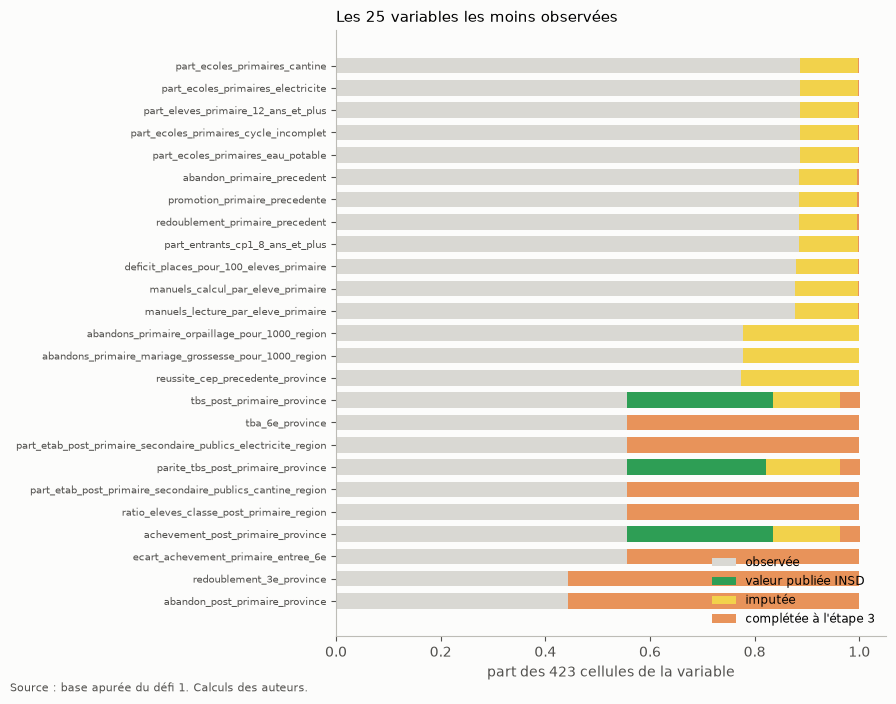

In [5]:
ordre = ["observée", "valeur publiée INSD", "imputée", "complétée à l'étape 3"]
couleurs = ["#d9d8d3", "#2e9e55", "#f2d24b", "#e8935a"]
t = part.reindex(columns=ordre).fillna(0).sort_values("observée").head(25)
fig, ax = plt.subplots(figsize=(9, 7))
gauche = 0
for statut, couleur in zip(ordre, couleurs):
    ax.barh(t.index, t[statut], left=gauche, color=couleur, label=statut, height=0.7)
    gauche = gauche + t[statut]
ax.set_xlabel("part des 423 cellules de la variable")
ax.tick_params(axis="y", labelsize=7.5)
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
ax.set_title("Les 25 variables les moins observées", loc="left", fontsize=11)
fig.text(0.01, 0.005, "Source : base apurée du défi 1. Calculs des auteurs.", fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

## 4. La cible : seules les valeurs observées servent au modèle

La cible de l'année t (abandon entre t et t+1) est la valeur `abandon_primaire_precedent` de l'année t+1. Les taux aberrants, ceux d'une province sans élève et ceux des provinces scindées ont été imputés pour que la base soit complète ; ils ne doivent ni entraîner ni évaluer un modèle.

In [6]:
cible = statuts[statuts["variable"] == "abandon_primaire_precedent"]
pd.crosstab(cible["annee_scolaire"], cible["statut"])

statut,complétée à l'étape 3,imputée,observée
annee_scolaire,,,
2016-2017,0,4,43
2017-2018,0,4,43
2018-2019,0,4,43
2019-2020,0,4,43
2020-2021,0,4,43
2021-2022,0,4,43
2022-2023,1,6,40
2023-2024,1,12,34
2024-2025,0,5,42


## 5. Les méthodes appliquées

In [7]:
journal = tables["journal_apurement"]
journal[journal["nature"] != "recodage"].groupby(["etape", "methode"]).agg(
    valeurs=("variable", "size"), variables=("variable", "nunique")).sort_values("valeurs", ascending=False)

valeurs  \
etape methode                                                                        
1     report de l'année suivante                                              1033   
3     régression à effets fixes (TBS et achèvement post-primaire sourcés)      559   
2     valeur publiée INSD                                                      348   
3     report/interpolation (voisin le plus proche)                             301   
1     médiane de l'ancienne région et de l'année                               192   
3     identité (achèvement primaire − TBA 6e)                                  172   
      moyenne de l'unité                                                       172   
2     report année précédente                                                  129   
3     médiane de l'ancienne région et de l'année                               120   
1     report de l'année précédente                                             116   
      médiane de la province                                                   103   
3     tendance linéaire de l'unité                                              86   
1     identité comptable (100 − abandon − redoublement)                         47   
      moyenne de la province                                                    43   
3     province d'origine (annuaire INSD), valeur publiée                        36   
      interpolation linéaire                                                    28   
1     interpolation linéaire                                                    26   
      copie de la variable de référence imputée                                 22   
2     report de l'année suivante                                                20   
      report de l'année précédente                                              19   
3     province d'origine, report de 2023-2024                                   12   
      copie de la variable de référence                                          4   
      identité comptable                                                         2   
1     tendance linéaire locale                                                   2   

                                                                           variables  
etape methode                                                                         
1     report de l'année suivante                                                  23  
3     régression à effets fixes (TBS et achèvement post-primaire sourcés)          3  
2     valeur publiée INSD                                                          3  
3     report/interpolation (voisin le plus proche)                                 3  
1     médiane de l'ancienne région et de l'année                                  29  
3     identité (achèvement primaire − TBA 6e)                                      1  
      moyenne de l'unité                                                           1  
2     report année précédente                                                      3  
3     médiane de l'ancienne région et de l'année                                   7  
1     report de l'année précédente                                                 3  
      médiane de la province                                                       4  
3     tendance linéaire de l'unité                                                 1  
1     identité comptable (100 − abandon − redoublement)                            1  
      moyenne de la province                                                       1  
3     province d'origine (annuaire INSD), valeur publiée                           3  
      interpolation linéaire                                                      25  
1     interpolation linéaire                                                       7  
      copie de la variable de référence imputée                                    2  
2     report de l'année suivante                                                   3  
      repor

In [8]:
journal[journal["nature"] == "recodage"].groupby(["methode", "detail"]).size().to_frame("cellules")

cellules
methode                               detail                                                                        
valeur aberrante recodée en manquant  taux d'abandon, de redoublement ou de promotion hors de [-5 ; 105] %        55
                                      taux de réussite supérieur à 105 %                                           1
valeur infinie recodée en manquant    division par zéro à la source                                                7
valeur sans objet recodée en manquant taux calculé sur une base de 0 élève                                         5

## 6. Les valeurs publiées par l'INSD

Chaque valeur des annuaires régionaux est comparée au panel en 2018-2019 et en 2022-2023 (0,6 point près ; 0,03 pour la parité). Les valeurs des années voisines ne sont retenues que si la comparaison est conforme.

In [9]:
controle = tables["sources_insd_controle"]
pd.crosstab(controle["variable"], controle["conforme"].map({True: "conforme", False: "non conforme"}).fillna("non comparable"))

conforme,conforme,non comparable,non conforme
variable,,,
achevement_post_primaire_province,85,1,0
parite_tbs_post_primaire_province,75,2,9
tbs_post_primaire_province,81,1,4


In [10]:
tables["sources_insd_rejetees"][["province_nom", "annee_scolaire", "variable", "valeur", "region_annuaire"]]

,province_nom,annee_scolaire,variable,valeur,region_annuaire
0,Bam,2016-2017,tbs_post_primaire_province,40.1000,Centre-Nord
1,Bam,2017-2018,tbs_post_primaire_province,42.7000,Centre-Nord
2,Bam,2016-2017,parite_tbs_post_primaire_province,1.1079,Centre-Nord
3,Bam,2017-2018,parite_tbs_post_primaire_province,1.2208,Centre-Nord
4,Bam,2023-2024,parite_tbs_post_primaire_province,0.6531,Centre-Nord
5,Banwa,2023-2024,parite_tbs_post_primaire_province,0.8977,Boucle du Mouhoun
6,Boulgou,2023-2024,parite_tbs_post_primaire_province,1.3742,Centre-Est
7,Koulpelogo,2023-2024,tbs_post_primaire_province,9.6000,Centre-Est
8,Koulpelogo,2023-2024,parite_tbs_post_primaire_province,0.9394,Centre-Est
9,Kourittenga,2023-2024,tbs_post_primaire_province,41.7000,Centre-Est


## 7. Les provinces scindées

Djelgodji et Karo-Peli (issues du Soum), Dyamongou et Gobnangou (issues de la Tapoa) gardent les valeurs reconstruites à l'étape 03 par les communes ; l'apurement ne comble que leurs cellules vides : post-primaire de la province d'origine publié par l'INSD, médiane de l'ancienne région pour le reste.

In [11]:
scindees = statuts[statuts["province_nom"].isin(["Djelgodji", "Karo-Peli", "Dyamongou", "Gobnangou"])]
pd.crosstab(scindees["province_nom"], scindees["statut"])

statut,complétée à l'étape 3,imputée,observée
province_nom,,,
Djelgodji,42,57,522
Dyamongou,42,57,522
Gobnangou,42,57,522
Karo-Peli,42,57,522


## 8. Dépôt au format du challenge

In [12]:
depot = exporter_transformation(version=1)
depot[depot["fichier_produit"].str.contains("base_apuree")][["fichier_depose", "role"]]

,fichier_depose,role
6,EXX_03-transformation_D1_engineer_base-apuree-province-2025-sans-cellule-vide_v1.csv,engineer
7,EXX_03-transformation_D1_engineer_statut-cellules-base-apuree_v1.csv,engineer
8,EXX_03-transformation_D1_engineer_journal-apurement_v1.csv,engineer
9,EXX_03-transformation_D1_engineer_classeur-base-apuree_v1.xlsx,engineer
10,EXX_03-transformation_D1_engineer_controles-apurement_v1.csv,engineer


## Suite

L'étape 04 entraîne le modèle de l'abandon de l'année suivante sur les cibles observées seulement, en imputant ses variables explicatives à l'intérieur de chaque pli de la validation temporelle, avec le seul passé.